In [2]:
import pandas as pd

In [3]:
from pathlib import Path

project_dir = Path.cwd().parent
file_path = project_dir / "data" / "application_train.csv"

df = pd.read_csv(file_path)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 307511
Number of columns: 122


In [4]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [6]:
df.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE                str
CODE_GENDER                       str
FLAG_OWN_CAR                      str
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

In [7]:
missing_values = df.isnull().sum()

missing_summary = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Columns with missing values:", len(missing_summary))
print(missing_summary.head(15))

Columns with missing values: 67
COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
dtype: int64


In [8]:
print(df["TARGET"].value_counts())

print("\nTarget proportions:")
print(df["TARGET"].value_counts(normalize=True).mul(100).round(2))

TARGET
0    282686
1     24825
Name: count, dtype: int64

Target proportions:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [9]:
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean().mul(100).round(2)
    ),
    "Unique Values": df.nunique()
})

quality_report = quality_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

quality_report.head(20)

,Data Type,Missing Count,Missing Percentage,Unique Values
COMMONAREA_AVG,float64,214865,69.87,3181
COMMONAREA_MODE,float64,214865,69.87,3128
COMMONAREA_MEDI,float64,214865,69.87,3202
NONLIVINGAPARTMENTS_MEDI,float64,213514,69.43,214
NONLIVINGAPARTMENTS_MODE,float64,213514,69.43,167
NONLIVINGAPARTMENTS_AVG,float64,213514,69.43,386
FONDKAPREMONT_MODE,str,210295,68.39,4
LIVINGAPARTMENTS_AVG,float64,210199,68.35,1868
LIVINGAPARTMENTS_MEDI,float64,210199,68.35,1097
LIVINGAPARTMENTS_MODE,float64,210199,68.35,736


In [10]:
key_columns = [
    "TARGET",
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "OCCUPATION_TYPE",
    "CNT_FAM_MEMBERS",
]

available_columns = [
    col for col in key_columns if col in df.columns
]

print("Available key columns:", len(available_columns))
print(available_columns)

df[available_columns].head()

Available key columns: 18
['TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS']


,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Working,Secondary / secondary special,Single / not married,House / apartment,-9461,-637,Laborers,1.0
1,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,State servant,Higher education,Married,House / apartment,-16765,-1188,Core staff,2.0
2,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Working,Secondary / secondary special,Single / not married,House / apartment,-19046,-225,Laborers,1.0
3,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Working,Secondary / secondary special,Civil marriage,House / apartment,-19005,-3039,Laborers,2.0
4,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Working,Secondary / secondary special,Single / not married,House / apartment,-19932,-3038,Core staff,1.0


In [11]:
financial_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
]

financial_summary = df[financial_columns].describe().round(2)

financial_summary

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.075110e+05,307511.00,307499.00,307233.00
mean,1.687979e+05,599026.00,27108.57,538396.21
std,2.371231e+05,402490.78,14493.74,369446.46
min,2.565000e+04,45000.00,1615.50,40500.00
25%,1.125000e+05,270000.00,16524.00,238500.00
50%,1.471500e+05,513531.00,24903.00,450000.00
75%,2.025000e+05,808650.00,34596.00,679500.00
max,1.170000e+08,4050000.00,258025.50,4050000.00


In [12]:
key_missing = pd.DataFrame({
    "Missing Count": df[available_columns].isnull().sum(),
    "Missing Percentage": (
        df[available_columns].isnull().mean() * 100
    ).round(2)
})

key_missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
OCCUPATION_TYPE,96391,31.35
AMT_GOODS_PRICE,278,0.09
NAME_CONTRACT_TYPE,0,0.00
TARGET,0,0.00
FLAG_OWN_REALTY,0,0.00
CODE_GENDER,0,0.00
CNT_CHILDREN,0,0.00
AMT_INCOME_TOTAL,0,0.00
AMT_CREDIT,0,0.00
FLAG_OWN_CAR,0,0.00


In [13]:
income_percentiles = df["AMT_INCOME_TOTAL"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

print("Income percentiles:")
print(income_percentiles)

print("\nHighest 10 income records:")
print(
    df[["AMT_INCOME_TOTAL", "AMT_CREDIT", "TARGET"]]
    .sort_values("AMT_INCOME_TOTAL", ascending=False)
    .head(10)
)

Income percentiles:
0.500    147150.0
0.750    202500.0
0.900    270000.0
0.950    337500.0
0.990    472500.0
0.999    900000.0
Name: AMT_INCOME_TOTAL, dtype: float64

Highest 10 income records:
        AMT_INCOME_TOTAL  AMT_CREDIT  TARGET
12840        117000000.0    562491.0       1
203693        18000090.0    675000.0       0
246858        13500000.0   1400503.5       0
77768          9000000.0   1431531.0       0
131127         6750000.0    790830.0       0
103006         4500000.0   2250000.0       0
287463         4500000.0   1755000.0       0
187833         4500000.0    835380.0       0
204564         4500000.0    450000.0       0
181698         3950059.5    675000.0       0


In [14]:
risk_comparison = df.groupby("TARGET").agg(
    Applicant_Count=("TARGET", "size"),
    Average_Income=("AMT_INCOME_TOTAL", "mean"),
    Median_Income=("AMT_INCOME_TOTAL", "median"),
    Average_Credit=("AMT_CREDIT", "mean"),
    Median_Credit=("AMT_CREDIT", "median"),
    Average_Annuity=("AMT_ANNUITY", "mean"),
    Median_Annuity=("AMT_ANNUITY", "median")
).round(2)

risk_comparison

,Applicant_Count,Average_Income,Median_Income,Average_Credit,Median_Credit,Average_Annuity,Median_Annuity
TARGET,,,,,,,
0,282686,169077.72,148500.0,602648.28,517788.0,27163.62,24876.0
1,24825,165611.76,135000.0,557778.53,497520.0,26481.74,25263.0


In [15]:
df["CREDIT_TO_INCOME_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
)

print(
    df["CREDIT_TO_INCOME_RATIO"]
    .describe()
    .round(2)
)

count    307511.00
mean          3.96
std           2.69
min           0.00
25%           2.02
50%           3.27
75%           5.16
max          84.74
Name: CREDIT_TO_INCOME_RATIO, dtype: float64


In [16]:
import pandas as pd

ratio_bins = [0, 2, 4, 6, 10, float("inf")]

ratio_labels = [
    "0–2x",
    "2–4x",
    "4–6x",
    "6–10x",
    "Above 10x"
]

df["CREDIT_INCOME_BAND"] = pd.cut(
    df["CREDIT_TO_INCOME_RATIO"],
    bins=ratio_bins,
    labels=ratio_labels,
    include_lowest=True
)

ratio_analysis = df.groupby(
    "CREDIT_INCOME_BAND",
    observed=False
).agg(
    Applicant_Count=("TARGET", "size"),
    Applicants_With_Difficulties=("TARGET", "sum"),
    Difficulty_Rate=("TARGET", "mean")
)

ratio_analysis["Difficulty_Rate"] = (
    ratio_analysis["Difficulty_Rate"] * 100
).round(2)

ratio_analysis

,Applicant_Count,Applicants_With_Difficulties,Difficulty_Rate
CREDIT_INCOME_BAND,,,
0–2x,76338,5671,7.43
2–4x,113561,10073,8.87
4–6x,62887,5114,8.13
6–10x,44881,3294,7.34
Above 10x,9844,673,6.84


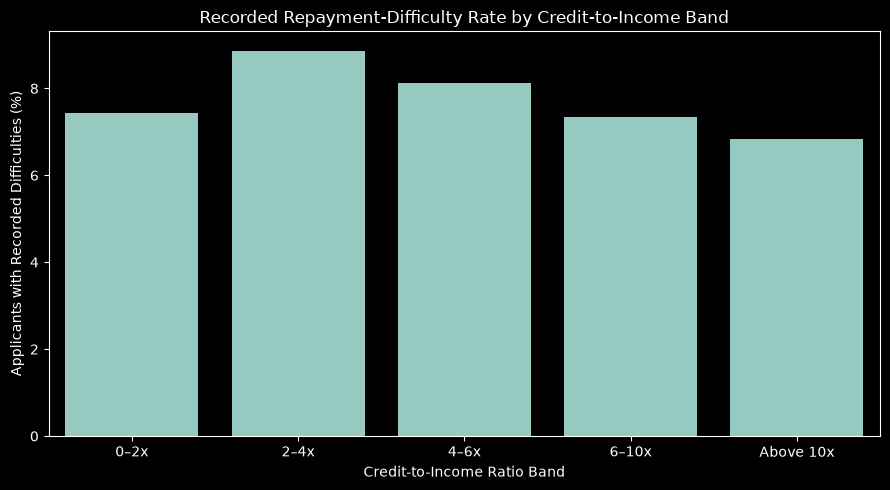

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = ratio_analysis.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="CREDIT_INCOME_BAND",
    y="Difficulty_Rate"
)

plt.title(
    "Recorded Repayment-Difficulty Rate by Credit-to-Income Band"
)
plt.xlabel("Credit-to-Income Ratio Band")
plt.ylabel("Applicants with Recorded Difficulties (%)")

plt.tight_layout()
plt.show()

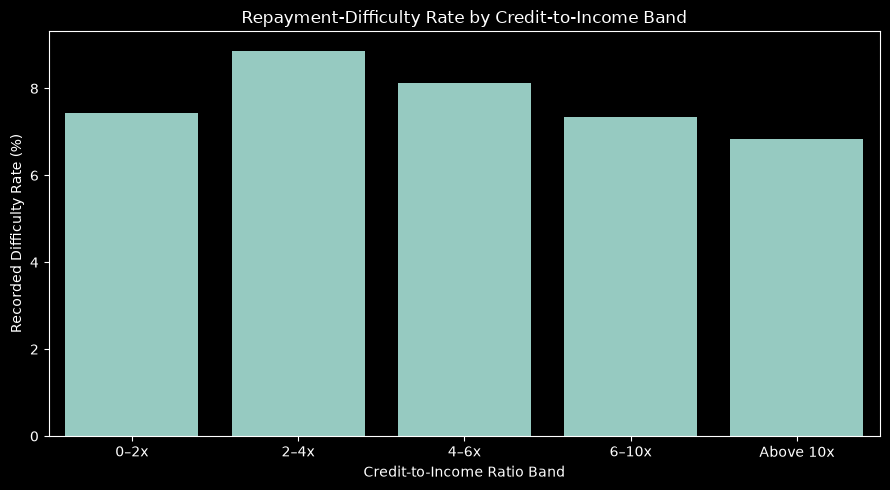

Chart saved to: c:\Users\Sudip\OneDrive\Desktop\FinTech-Loan-Analytics\reports\credit_income_difficulty_rate.png


In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

project_dir = Path.cwd().parent
reports_dir = project_dir / "reports"
reports_dir.mkdir(exist_ok=True)

plot_data = ratio_analysis.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="CREDIT_INCOME_BAND",
    y="Difficulty_Rate"
)

plt.title("Repayment-Difficulty Rate by Credit-to-Income Band")
plt.xlabel("Credit-to-Income Ratio Band")
plt.ylabel("Recorded Difficulty Rate (%)")

plt.tight_layout()

chart_path = reports_dir / "credit_income_difficulty_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

In [19]:
contract_analysis = df.groupby(
    "NAME_CONTRACT_TYPE",
    observed=False
).agg(
    Applicant_Count=("TARGET", "size"),
    Applicants_With_Difficulties=("TARGET", "sum"),
    Difficulty_Rate=("TARGET", "mean")
)

contract_analysis["Difficulty_Rate"] = (
    contract_analysis["Difficulty_Rate"] * 100
).round(2)

contract_analysis.sort_values(
    "Difficulty_Rate",
    ascending=False
)

,Applicant_Count,Applicants_With_Difficulties,Difficulty_Rate
NAME_CONTRACT_TYPE,,,
Cash loans,278232,23221,8.35
Revolving loans,29279,1604,5.48


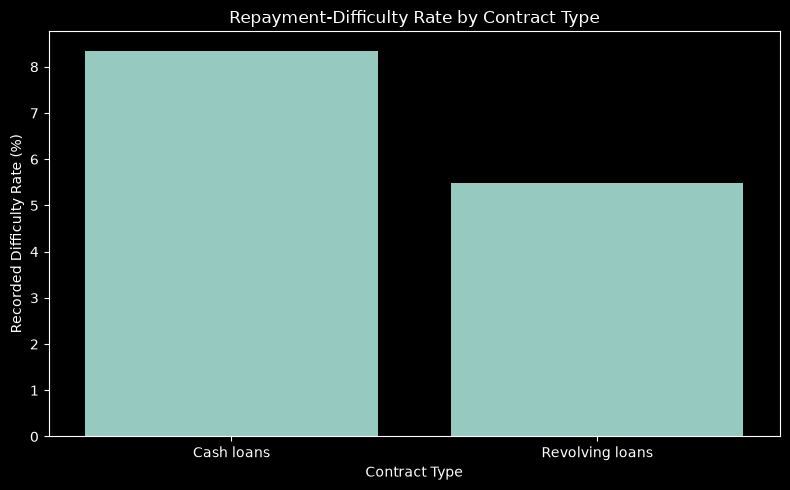

Chart saved to: c:\Users\Sudip\OneDrive\Desktop\FinTech-Loan-Analytics\reports\contract_type_difficulty_rate.png


In [20]:
contract_plot = contract_analysis.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_plot,
    x="NAME_CONTRACT_TYPE",
    y="Difficulty_Rate"
)

plt.title("Repayment-Difficulty Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Recorded Difficulty Rate (%)")

plt.tight_layout()

chart_path = reports_dir / "contract_type_difficulty_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

In [21]:
income_bins = [0, 100000, 150000, 200000, 300000, float("inf")]

income_labels = [
    "Up to 1L",
    "1L–1.5L",
    "1.5L–2L",
    "2L–3L",
    "Above 3L"
]

df["INCOME_BAND"] = pd.cut(
    df["AMT_INCOME_TOTAL"],
    bins=income_bins,
    labels=income_labels,
    include_lowest=True
)

income_analysis = df.groupby(
    "INCOME_BAND",
    observed=False
).agg(
    Applicant_Count=("TARGET", "size"),
    Applicants_With_Difficulties=("TARGET", "sum"),
    Difficulty_Rate=("TARGET", "mean")
)

income_analysis["Difficulty_Rate"] = (
    income_analysis["Difficulty_Rate"] * 100
).round(2)

income_analysis

,Applicant_Count,Applicants_With_Difficulties,Difficulty_Rate
INCOME_BAND,,,
Up to 1L,63698,5225,8.20
1L–1.5L,91591,7894,8.62
1.5L–2L,64307,5432,8.45
2L–3L,65176,4921,7.55
Above 3L,22739,1353,5.95


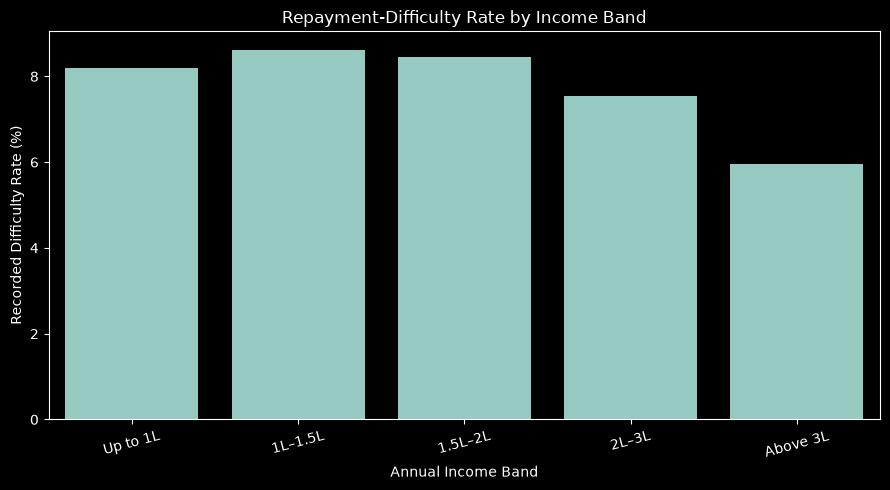

Chart saved to: c:\Users\Sudip\OneDrive\Desktop\FinTech-Loan-Analytics\reports\income_band_difficulty_rate.png


In [22]:
income_plot = income_analysis.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=income_plot,
    x="INCOME_BAND",
    y="Difficulty_Rate"
)

plt.title("Repayment-Difficulty Rate by Income Band")
plt.xlabel("Annual Income Band")
plt.ylabel("Recorded Difficulty Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()

chart_path = reports_dir / "income_band_difficulty_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

In [23]:
findings = pd.DataFrame([
    {
        "Analysis": "Credit-to-Income Band",
        "Key Finding": "2–4x band had the highest observed rate",
        "Observed Rate (%)": 8.87
    },
    {
        "Analysis": "Contract Type",
        "Key Finding": "Cash loans had a higher observed rate",
        "Observed Rate (%)": 8.35
    },
    {
        "Analysis": "Income Band",
        "Key Finding": "Above 3L band had the lowest observed rate",
        "Observed Rate (%)": 5.95
    }
])

findings

,Analysis,Key Finding,Observed Rate (%)
0,Credit-to-Income Band,2–4x band had the highest observed rate,8.87
1,Contract Type,Cash loans had a higher observed rate,8.35
2,Income Band,Above 3L band had the lowest observed rate,5.95


In [24]:
findings_path = reports_dir / "key_findings.csv"

findings.to_csv(findings_path, index=False)

print("Findings table saved to:", findings_path)

Findings table saved to: c:\Users\Sudip\OneDrive\Desktop\FinTech-Loan-Analytics\reports\key_findings.csv
